---
title: "Section 1: Where is nightlife in Singapore?"
format:
  html:
    code-fold: true
    code-summary: "Show code"
---

This section will extract point data of nightlife venues in Singapore from OSM across 3 categories of nightlife and explore its spatial patterns. Spatial clustering patterns will be identified using DBSCAN.

## 1. Setting up environment

In [9]:
import io
import os
from getpass import getpass
import warnings
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import plotly.express as px
from pathlib import Path
import altair as alt
import networkx as nx
from IPython.display import display

warnings.filterwarnings("ignore")

# Configure OSMnx
ox.settings.use_cache = True
ox.settings.log_console = False

print("OSMnx version:", ox.__version__)
print("GeoPandas version:", gpd.__version__)

OSMnx version: 2.1.1
GeoPandas version: 1.1.3


## 2. Data gathering and cleaning
I will obtain the

1. Singapore main island boundary dataset from the 2025 Masterplan, calling an API from [data.gov.sg](https://data.gov.sg/datasets?formats=GEOJSON|KML|SHP|KMZ&sort=relevancy&query=singapore+boundary&resultId=d_2cc750190544007400b2cfd5d7f53209).

2. Point data of nightlife establishments from OSM.

### 2a. Singapore Boundary

In [37]:
# singapore boundary
# a window will pop up requesting API key

api_key = os.environ.get("DATAGOV_API_KEY", "").strip()
if not api_key:
    api_key = getpass("Data.gov.sg API key (hidden): ").strip()

headers = {"x-api-key": api_key}
dataset_id = "d_2cc750190544007400b2cfd5d7f53209"
poll_url = f"https://api-open.data.gov.sg/v1/public/api/datasets/{dataset_id}/poll-download"

# 2. Request the download URL
response = requests.get(poll_url, headers=headers)
json_data = response.json()

if json_data.get("code") != 0:
    raise RuntimeError(f"Data.gov.sg API error: {json_data.get('errMsg', json_data)}")

download_url = json_data["data"]["url"]

# 3. Download the GeoJSON directly into a GeoDataFrame
data_response = requests.get(download_url)
data_response.raise_for_status()

regions = gpd.read_file(io.BytesIO(data_response.content))

regions.head(5)

Data.gov.sg API key (hidden):  ········


,OBJECTID,PLN_AREA_N,PLN_AREA_C,CA_IND,REGION_N,REGION_C,INC_CRC,FMEL_UPD_D,SHAPE.AREA,SHAPE.LEN,geometry
0,28,BUKIT TIMAH,BT,N,CENTRAL REGION,CR,A3BFBAC3EBE4A93B,20251229123848,1.751829e+07,22652.993950,"POLYGON ((103.79644 1.34888, 103.79569 1.34917, 103.7952..."
1,29,CLEMENTI,CL,N,WEST REGION,WR,4D34F1FA6471066E,20251229123848,9.523534e+06,15044.652233,"POLYGON ((103.75867 1.29922, 103.76102 1.30103, 103.7613..."
2,30,JURONG EAST,JE,N,WEST REGION,WR,CB9A67C633D272C7,20251229123848,1.786953e+07,26938.090843,"POLYGON ((103.75728 1.29837, 103.75726 1.29842, 103.7553..."
3,31,NOVENA,NV,N,CENTRAL REGION,CR,163B19CA54A679AF,20251229123848,8.968012e+06,14804.900494,"POLYGON ((103.83599 1.34168, 103.83598 1.34168, 103.8352..."
4,32,QUEENSTOWN,QT,N,CENTRAL REGION,CR,6FEECCA10F1E3D3C,20251229123848,2.168363e+07,34363.162430,"POLYGON ((103.79831 1.26663, 103.79921 1.2682, 103.80028..."


<Axes: >

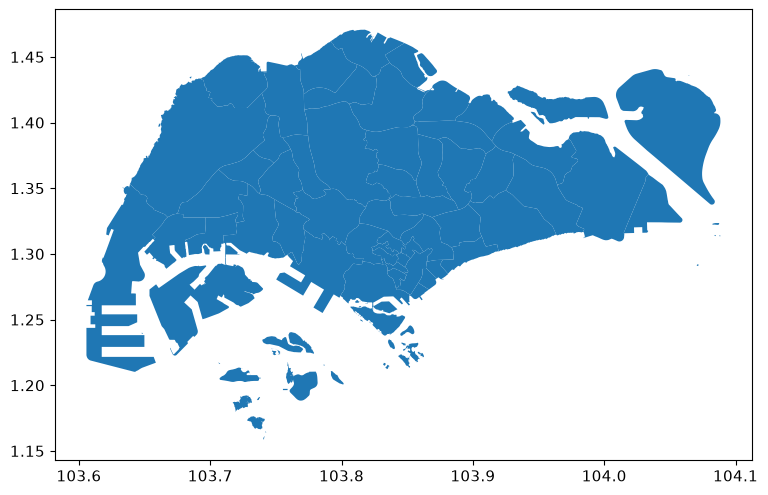

In [38]:
regions.plot()

**Data wrangling**

The planning areas were downloaded. As seen, surrounding islands were also plotted which do not have nightlife, nor public transport access. Hence only the areas in the main island will be extracted, and unionised into a single boundary. This is done by removing any entries where the PLN_AREA_N column contains the word "ISLANDS".

In [13]:
regions = regions[~regions["PLN_AREA_N"].str.contains("ISLANDS", case=False, na=False)].copy()

print(f"Remaining features: {len(regions)}")

Remaining features: 52


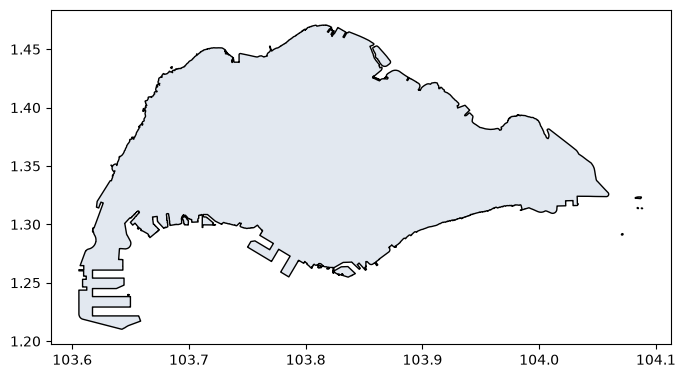

In [7]:
sg_boundary = (
    regions.to_crs(epsg=3414)
    .assign(geometry=lambda g: g.geometry.buffer(0.1))  # closes any small gaps
    .dissolve()
    .assign(geometry=lambda g: g.geometry.buffer(-0.1))  # restores exact outer edge
    .to_crs(regions.crs)
    [["geometry"]]
    .reset_index(drop=True)
)

sg_boundary.plot(figsize=(8, 5), edgecolor="black", facecolor="#e2e8f0")

# Save locally for reuse
os.makedirs("../../data", exist_ok=True)
sg_boundary.to_file("../../data/sg_mainland_boundary.geojson", driver="GeoJSON")

### 2b. Nightlife point data
Nightlife is defined using the Singapore Standard Industrial Classification Code (SSIC) of

1. 56130: pubs

2. 93203: night clubs, discotheques, dance clubs, and karaoke lounges

3. 93202: game arcade, online game aggregator, LAN game operators and gaming centres

Data points are extracted from OSM using a list of values from keys like "amenity", and clipped using the Singapore boundary I sourced above.

In [16]:
# Keep table previews readable. Do not suppress numerical warnings globally.
pd.options.display.max_columns = 12
pd.options.display.max_colwidth = 60
plt.rcParams.update({"figure.figsize": (9, 6), "font.size": 11})

# define osm tags mapped to the three ssic categories
nightlife_tags = {
    # ssic 56130: pubs (includes bar/biergarten tags commonly used for sg pubs)
    "amenity": [
        "pub",
        "bar",
        "biergarten",
        # ssic 93203: night clubs, discotheques, dance clubs, and karaoke lounges
        "nightclub",
        "karaoke_box",
        "music_venue",
        # ssic 93202: game arcades, lan game operators, and gaming centres
        "internet_cafe",
    ],
    "leisure": [
        "dance",                # ssic 93203
        "amusement_arcade",     # ssic 93202: game arcades
        "adult_gaming_centre",  # ssic 93202: gaming centres
    ],
    "karaoke": ["yes"],         # ssic 93203: karaoke lounges
}

# query osmnx using the dissolved mainland singapore polygon (needs to be in epsg:4326)
sg_polygon = sg_boundary.to_crs(epsg=4326).geometry.iloc[0]
gdf_raw = ox.features_from_polygon(sg_polygon, tags=nightlife_tags)
print(f"Raw features downloaded within mainland Singapore: {len(gdf_raw)}")

# project to singapore svy21 (epsg:3414, meters) so polygon centroids are accurate
gdf_proj = gdf_raw.to_crs(epsg=3414).copy()
gdf_proj["geometry"] = gdf_proj.geometry.centroid

Raw features downloaded within mainland Singapore: 652


In [15]:
print(gdf_proj["amenity"].dropna().unique())

<ArrowStringArray>
[          'bar',           'pub',     'nightclub', 'internet_cafe',
   'karaoke_box',    'biergarten',       'theatre',          'cafe']
Length: 8, dtype: str


In [39]:
print(gdf_proj["leisure"].dropna().unique())

<ArrowStringArray>
['dance', 'amusement_arcade', 'adult_gaming_centre']
Length: 3, dtype: str


**Data wrangling**

Upon inspection of the values within the amenity and leisure keys, Theatres and Cafes were included which we do not want in our nightlife dataset. They were probably accidentally included due to adding a "karaoke" tag to our call to capture karaoke bars. I will filter them out from our Geodataframe.

In [23]:
# drop theatres, cafes, and any entries missing a name
exclude_amenities = ["theatre", "cafe"]
gdf_proj = gdf_proj[
    (~gdf_proj["amenity"].isin(exclude_amenities))
    & (gdf_proj["name"].notna())
    & (gdf_proj["name"].astype(str).str.strip() != "")
].copy()

# classify each venue into its matching ssic code & label
def classify_ssic(row):
    amenity = str(row.get("amenity", ""))
    leisure = str(row.get("leisure", ""))
    karaoke = str(row.get("karaoke", ""))

    # ssic 93203: night clubs, discotheques, dance clubs, and karaoke lounges
    if amenity in ["nightclub", "karaoke_box", "music_venue"] or leisure == "dance" or karaoke == "yes":
        return "93203", "93203: Nightclubs, Dance & Karaoke"

    # ssic 93202: game arcade, lan game operators, and gaming centres
    elif leisure in ["amusement_arcade", "adult_gaming_centre"] or amenity == "internet_cafe":
        return "93202", "93202: Arcades & Gaming Centres"

    # ssic 56130: pubs
    elif amenity in ["pub", "bar", "biergarten"]:
        return "56130", "56130: Pubs & Bars"

    return "Other", "Other"

gdf_proj[["ssic_code", "ssic_category"]] = gdf_proj.apply(
    lambda r: pd.Series(classify_ssic(r)), axis=1
)

# keep useful columns and reproject back to wgs84 (epsg:4326) for web mapping & export
keep_cols = [
    c for c in ["name", "ssic_code", "ssic_category", "amenity", "leisure", "opening_hours", "geometry"]
    if c in gdf_proj.columns
]
nightlife_svy21 = gdf_proj[keep_cols].reset_index(drop=True)

nightlife_wgs84 = nightlife_svy21.to_crs(epsg=4326)
nightlife_wgs84["lon"] = nightlife_wgs84.geometry.x
nightlife_wgs84["lat"] = nightlife_wgs84.geometry.y

# save to the repo's data/ folder
os.makedirs("../../data", exist_ok=True)
output_path = "../../data/singapore_nightlife_ssic.geojson"
nightlife_wgs84.to_file(output_path, driver="GeoJSON")

print(f"Saved {len(nightlife_wgs84)} named venues to {output_path}\n")
print(nightlife_wgs84["ssic_category"].value_counts())

Saved 620 named venues to ../../data/singapore_nightlife_ssic.geojson

ssic_category
56130: Pubs & Bars                    445
93203: Nightclubs, Dance & Karaoke    111
93202: Arcades & Gaming Centres        64
Name: count, dtype: int64


The final Geodataframe only contains venues that we want in the dataset. It will be saved as a geojson for further use.

## 3. Visualization
I now investigate the types of nightlife venues, their operating hours and their spatial distribution.

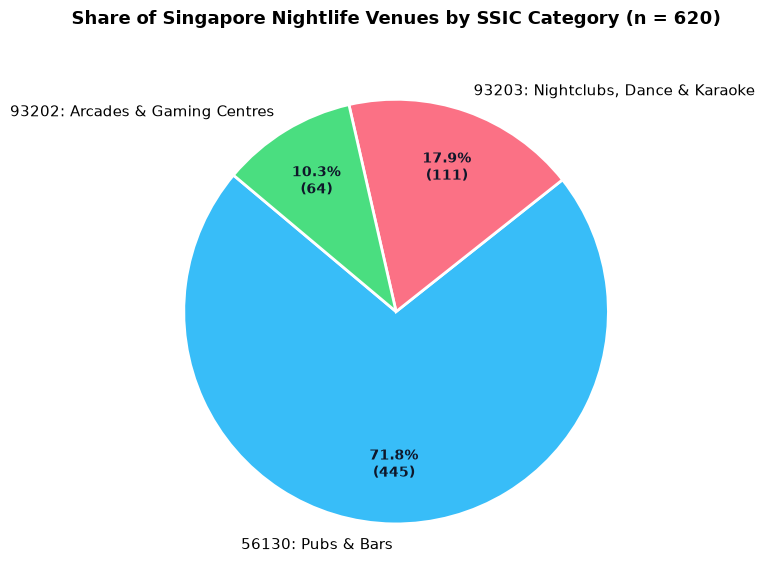

In [27]:
# count venues by ssic category
counts = nightlife_wgs84["ssic_category"].value_counts()

# match colors from your folium map
color_map = {
    "56130: Pubs & Bars": "#38bdf8",
    "93203: Nightclubs, Dance & Karaoke": "#fb7185",
    "93202: Arcades & Gaming Centres": "#4ade80",
}
colors = [color_map.get(cat, "#94a3b8") for cat in counts.index]

# format labels with both count and percentage
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n({val:,})"
    return my_autopct

fig, ax = plt.subplots(figsize=(8, 6))
wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=counts.index,
    autopct=make_autopct(counts.values),
    startangle=140,
    colors=colors,
    pctdistance=0.72,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)

for autotext in autotexts:
    autotext.set_color("#0f172a")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(10)

ax.set_title(
    f"Share of Singapore Nightlife Venues by SSIC Category (n = {len(nightlife_wgs84):,})",
    fontsize=13,
    fontweight="bold",
    pad=16,
)
plt.tight_layout()
plt.show()

Venues with opening hours listed: 76 out of 620


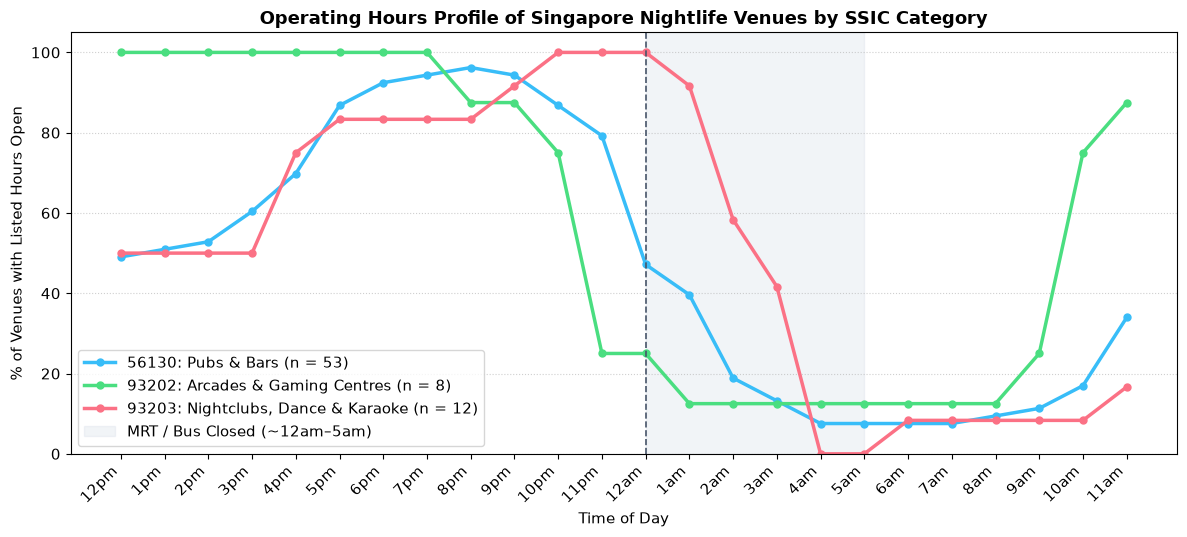

In [31]:
import re
# filter to venues that have opening hours listed
hours_df = nightlife_wgs84[
    nightlife_wgs84["opening_hours"].notna()
    & (nightlife_wgs84["opening_hours"].astype(str).str.strip() != "")
].copy()

print(f"Venues with opening hours listed: {len(hours_df)} out of {len(nightlife_wgs84)}")

# parse osm opening_hours strings into a list of active hours (0-23)
def parse_open_hours(hours_str):
    s = str(hours_str).strip()
    if "24/7" in s:
        return list(range(24))

    active_hours = set()
    # match all HH:MM-HH:MM time ranges in the string
    matches = re.findall(r"(\d{1,2}):(\d{2})\s*-\s*(\d{1,2}):(\d{2})", s)

    for sh, sm, eh, em in matches:
        start = int(sh) % 24
        end = int(eh) % 24
        # include the closing hour if it closes past the top of the hour (e.g. 02:30)
        if int(em) > 0:
            end = (end + 1) % 24

        if start == end:
            active_hours.update(range(24))
        elif start < end:
            active_hours.update(range(start, end))
        else:
            # wraps past midnight (e.g. 18:00-03:00 -> 18..23 and 0..2)
            active_hours.update(range(start, 24))
            active_hours.update(range(0, end))

    return sorted(active_hours)

hours_df["open_hours_list"] = hours_df["opening_hours"].apply(parse_open_hours)

# keep only rows where at least one valid time range was parsed
hours_df = hours_df[hours_df["open_hours_list"].map(len) > 0].copy()

# order hours from noon (12) to 11am (11) so midnight sits cleanly in the middle
hour_order = list(range(12, 24)) + list(range(0, 12))
hour_labels = [f"{h % 12 or 12}{'pm' if h >= 12 else 'am'}" for h in hour_order]

color_map = {
    "56130: Pubs & Bars": "#38bdf8",
    "93203: Nightclubs, Dance & Karaoke": "#fb7185",
    "93202: Arcades & Gaming Centres": "#4ade80",
}

fig, ax = plt.subplots(figsize=(12, 5.5))

for cat, group in hours_df.groupby("ssic_category"):
    n_venues = len(group)
    # calculate % of venues in this ssic category open during each hour
    pct_open = [
        (group["open_hours_list"].apply(lambda hrs: h in hrs).sum() / n_venues) * 100
        for h in hour_order
    ]
    ax.plot(
        range(24),
        pct_open,
        marker="o",
        linewidth=2.5,
        markersize=5,
        color=color_map.get(cat, "#64748b"),
        label=f"{cat} (n = {n_venues})",
    )

# highlight the post-midnight transit gap window (12am - 5am)
midnight_idx = hour_order.index(0)
five_am_idx = hour_order.index(5)
ax.axvspan(midnight_idx, five_am_idx, color="#cbd5e1", alpha=0.25, label="MRT / Bus Closed (~12am–5am)")
ax.axvline(midnight_idx, color="#475569", linestyle="--", linewidth=1.2)

ax.set_xticks(range(24))
ax.set_xticklabels(hour_labels, rotation=45, ha="right")
ax.set_ylim(0, 105)
ax.set_ylabel("% of Venues with Listed Hours Open", fontsize=11)
ax.set_xlabel("Time of Day", fontsize=11)
ax.set_title("Operating Hours Profile of Singapore Nightlife Venues by SSIC Category", fontsize=13, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.show()


_While arcade operating hours follow a very different temporal pattern from bars/clubs, I thought it was important to include because it still does comprise evening social scenes in Singapore._

Pubs/bars and nightclubs/dance/karaoke surprsingly seem to open quite early from 3pm, with half already being open throughout the day. It seems most of nightlife venues in Singapore are not exclusive to the night. 

In [26]:
# ensure clean text values for hover tooltips
plot_df = nightlife_wgs84.copy()
plot_df["amenity_clean"] = plot_df["amenity"].fillna("N/A") if "amenity" in plot_df.columns else "N/A"
plot_df["hours_clean"] = plot_df["opening_hours"].fillna("Not listed") if "opening_hours" in plot_df.columns else "Not listed"

# initialize base map centered on singapore with esri dark gray base tiles
m = folium.Map(location=[1.3521, 103.8198], zoom_start=11.5, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors, and the GIS User Community",
    name="Esri Dark Gray Base",
).add_to(m)

# add mainland singapore boundary in the background
folium.GeoJson(
    sg_boundary.to_crs(epsg=4326),
    name="Singapore Boundary",
    style_function=lambda x: {
        "fillColor": "#94a3b8",
        "color": "#64748b",
        "weight": 1.2,
        "fillOpacity": 0.15,
    },
).add_to(m)

# color palette for the three ssic categories
color_map = {
    "56130: Pubs & Bars": "#38bdf8",
    "93203: Nightclubs, Dance & Karaoke": "#fb7185",
    "93202: Arcades & Gaming Centres": "#4ade80",
}

# plot each nightlife venue with a hover tooltip
for _, row in plot_df.iterrows():
    cat = row["ssic_category"]
    tooltip_html = (
        f"<b>{row['name']}</b><br>"
        f"Amenity: {row['amenity_clean']}<br>"
        f"Opening Hours: {row['hours_clean']}"
    )

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=5,
        color=color_map.get(cat, "#cbd5e1"),
        fill=True,
        fill_color=color_map.get(cat, "#cbd5e1"),
        fill_opacity=0.85,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(m)

# add floating header box at the top left (next to zoom controls)
header_html = """
<div style="position: fixed; top: 15px; left: 55px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 16px; border: 1px solid #334155; border-radius: 8px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-size: 16px; font-weight: 700; margin-bottom: 2px;">
    Singapore Nightlife Venues by SSIC Category
  </div>
  <div style="font-size: 12px; color: #cbd5e1;">
    Hover over any point for venue name, amenity type, and opening hours
  </div>
</div>
"""
m.get_root().html.add_child(folium.Element(header_html))

# add a simple legend in the bottom-right corner
legend_html = """
<div style="position: fixed; bottom: 30px; right: 30px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 14px; border: 1px solid #334155; border-radius: 8px; font-size: 13px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4);">
  <b>SSIC Category</b><br>
  <span style="color:#38bdf8;">●</span> 56130: Pubs & Bars<br>
  <span style="color:#fb7185;">●</span> 93203: Nightclubs, Dance & Karaoke<br>
  <span style="color:#4ade80;">●</span> 93202: Arcades & Gaming Centres
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

m

In [32]:
# filter to venues operating during post-midnight hours (12am to 5am)
post_midnight_hours = {0, 1, 2, 3, 4, 5}
after_midnight_df = hours_df[
    hours_df["open_hours_list"].apply(lambda hrs: bool(set(hrs) & post_midnight_hours))
].copy()

after_midnight_df["amenity_clean"] = (
    after_midnight_df["amenity"].fillna("N/A") if "amenity" in after_midnight_df.columns else "N/A"
)

# initialize base map centered on singapore with esri dark gray base tiles
m_midnight = folium.Map(location=[1.3521, 103.8198], zoom_start=11.5, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors, and the GIS User Community",
    name="Esri Dark Gray Base",
).add_to(m_midnight)

# add mainland singapore boundary in the background
folium.GeoJson(
    sg_boundary.to_crs(epsg=4326),
    name="Singapore Boundary",
    style_function=lambda x: {
        "fillColor": "#94a3b8",
        "color": "#64748b",
        "weight": 1.2,
        "fillOpacity": 0.15,
    },
).add_to(m_midnight)

# color palette for the three ssic categories
color_map = {
    "56130: Pubs & Bars": "#38bdf8",
    "93203: Nightclubs, Dance & Karaoke": "#fb7185",
    "93202: Arcades & Gaming Centres": "#4ade80",
}

# plot each post-midnight venue with a hover tooltip
for _, row in after_midnight_df.iterrows():
    cat = row["ssic_category"]
    tooltip_html = (
        f"<b>{row['name']}</b><br>"
        f"Amenity: {row['amenity_clean']}<br>"
        f"Opening Hours: {row['opening_hours']}"
    )

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=5.5,
        color=color_map.get(cat, "#cbd5e1"),
        fill=True,
        fill_color=color_map.get(cat, "#cbd5e1"),
        fill_opacity=0.85,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(m_midnight)

# add floating header box at the top left
header_html = f"""
<div style="position: fixed; top: 15px; left: 55px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 16px; border: 1px solid #334155; border-radius: 8px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-size: 16px; font-weight: 700; margin-bottom: 2px;">
    After-Midnight Nightlife Venues (Open Past 12:00 AM, n = {len(after_midnight_df)})
  </div>
  <div style="font-size: 12px; color: #cbd5e1;">
    Venues with listed hours operating during the MRT/bus shutdown window
  </div>
</div>
"""
m_midnight.get_root().html.add_child(folium.Element(header_html))

# add legend in the bottom-right corner
legend_html = """
<div style="position: fixed; bottom: 30px; right: 30px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 14px; border: 1px solid #334155; border-radius: 8px; font-size: 13px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4);">
  <b>SSIC Category</b><br>
  <span style="color:#38bdf8;">●</span> 56130: Pubs & Bars<br>
  <span style="color:#fb7185;">●</span> 93203: Nightclubs, Dance & Karaoke<br>
  <span style="color:#4ade80;">●</span> 93202: Arcades & Gaming Centres
</div>
"""
m_midnight.get_root().html.add_child(folium.Element(legend_html))

m_midnight

There are a total of 620 nightlife venues in Singapore, with pubs consituting 72% of them.

We see from the line graph that most nightlife venues remain open up till 9pm, with a rapid drop in numbers after 9pm. During 12am-5am when public transit is not functioning, we notice an extremely sharp drop in nightclubs, dance and karaoke venues, potentially due to a lack of transit options for patrons that shape the low demand for these venues past midnight. Arcades and gaming centres remain the most consistently open, with 10% of venues being open throughout the night.

### Spatial pattern

As expected, nightlife is most concentrated in Singapore's downtown, with pubs being most dispersed spatially (since it is also the most prevalent type of venue).

Out of the 39 venues that were recorded open past midnight, majority are concentrated in downtown, except for 4 karaoke venues located in the heartlands, 2 bars located in Holland Village (an expat neighborhood), and 1 bar in the airport. 

## 4. Clustering analysis using DBSCAN
I used DBSCAN clustering to determine the hotspots of nightlife in Singapore. Since there are 620 total recorded venues, and they are quite concentrated, I define epsilon as 250m (3-min walk) and min_samples as 8 to capture distinct nightlife districts without merging areas together.

_Sensitivity note: The parameters were chosen to avoid clustering Civic District (Cluster 1) with Clarke Quay (Cluster 0) because they are distinctly different venues and the cluster would be too big. However that also means Clusters 2 and 5 would have to be separated. Different thresholds could be played around with more in the future to decide the optimal parameters for Singapore's nightlife geography._

In [45]:
# reproject cluster polygons and points to wgs84 (epsg:4326) for folium
clusters_wgs84 = nightlife_clusters_gdf.to_crs(epsg=4326)
coords_wgs84 = coords.to_crs(epsg=4326)
coords_wgs84["lon"] = coords_wgs84.geometry.x
coords_wgs84["lat"] = coords_wgs84.geometry.y

# generate distinct hex colors for each cluster
cmap = plt.get_cmap("tab20", max(num_clusters, 1))
cluster_colors = {i: mcolors.to_hex(cmap(i)) for i in range(num_clusters)}

# initialize base map with esri dark gray base tiles
m_dbscan = folium.Map(location=[1.3521, 103.8198], zoom_start=11.5, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors, and the GIS User Community",
    name="Esri Dark Gray Base",
    control=False,
).add_to(m_dbscan)

# add mainland singapore boundary in the background
folium.GeoJson(
    sg_boundary.to_crs(epsg=4326),
    name="Singapore Boundary",
    control=False,
    style_function=lambda x: {
        "fillColor": "#94a3b8",
        "color": "#64748b",
        "weight": 1.2,
        "fillOpacity": 0.12,
    },
).add_to(m_dbscan)

# create toggleable feature groups
fg_polygons = folium.FeatureGroup(name="Cluster Polygons (40m Hull)", show=True)
fg_clustered = folium.FeatureGroup(name=f"Clustered Venues (n = {num_points - num_noise})", show=True)
fg_noise = folium.FeatureGroup(name=f"Noise Points / Isolated (n = {num_noise})", show=True)

# plot cluster polygons with hover tooltips
for _, row in clusters_wgs84.iterrows():
    cid = int(row["cluster_id"])
    color = cluster_colors[cid]
    tooltip_html = f"<b>Cluster {cid}</b><br>Venues in cluster: {row['venue_count']}"

    folium.GeoJson(
        row["geometry"],
        style_function=lambda x, c=color: {
            "fillColor": c,
            "color": c,
            "weight": 2,
            "fillOpacity": 0.28,
        },
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(fg_polygons)

# plot noise points in grey
noise_wgs84 = coords_wgs84[coords_wgs84["label"] == -1]
for _, row in noise_wgs84.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=3.5,
        color="#64748b",
        fill=True,
        fill_color="#64748b",
        fill_opacity=0.55,
        tooltip=folium.Tooltip(f"<b>{row['name']}</b><br>Status: Noise (isolated)"),
    ).add_to(fg_noise)

# plot clustered venues colored by their cluster
clustered_wgs84 = coords_wgs84[coords_wgs84["label"] != -1]
for _, row in clustered_wgs84.iterrows():
    cid = int(row["label"])
    color = cluster_colors[cid]
    tooltip_html = (
        f"<b>{row['name']}</b><br>"
        f"Cluster: {cid}<br>"
        f"Category: {row['ssic_category']}"
    )
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4.5,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.9,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(fg_clustered)

fg_polygons.add_to(m_dbscan)
fg_noise.add_to(m_dbscan)
fg_clustered.add_to(m_dbscan)

# add layer control in top-right so users can toggle noise points or polygons
folium.LayerControl(position="topright", collapsed=False).add_to(m_dbscan)

# add floating header box
header_html = f"""
<div style="position: fixed; top: 15px; left: 55px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 16px; border: 1px solid #334155; border-radius: 8px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-size: 16px; font-weight: 700; margin-bottom: 2px;">
    Singapore Nightlife DBSCAN Clusters (eps = {eps}m, min_samples = {min_samples})
  </div>
  <div style="font-size: 12px; color: #cbd5e1;">
    {num_clusters} clusters identified | Hover over polygons or points and toggle layers at top-right
  </div>
</div>
"""
m_dbscan.get_root().html.add_child(folium.Element(header_html))

# add compact legend in bottom-right corner
legend_html = f"""
<div style="position: fixed; bottom: 30px; right: 30px; z-index: 9999; background: rgba(15, 23, 42, 0.92);
            color: #f8fafc; padding: 10px 14px; border: 1px solid #334155; border-radius: 8px; font-size: 12.5px;
            line-height: 1.6; box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-weight: 700; margin-bottom: 4px; font-size: 13px;">DBSCAN Classification</div>
  <span style="display:inline-block;width:11px;height:11px;background:#38bdf8;opacity:0.45;border:1.5px solid #38bdf8;margin-right:6px;"></span>Cluster Boundary (n = {num_clusters})<br>
  <span style="color:#38bdf8;">●</span> Clustered Venue (n = {num_points - num_noise})<br>
  <span style="color:#64748b;">●</span> Noise / Isolated Venue (n = {num_noise})
</div>
"""
m_dbscan.get_root().html.add_child(folium.Element(legend_html))

m_dbscan

Cluster 0 (blue) is the largest cluster with 165 venues. It is located at Clarke Quay, with iconic riverfront clubs and Tanjong Pagar, with shophouses and cocktail bars.

North of that is Cluster 1 (orange) with 165 venues. It encompasses the Civic District, with many shophouses and cocktail bars, and Bencoolen, a student/creative corridor with lively bars and karaoke spots.

There are other smaller clusters outside of Central Singapore such as in Geylang (pink cluster) which is the red-light district of Singapore.

Noise points constitute 40% (242 out of 620) of all venues, suggesting both high clustering and high dispersion outside of Central Singapore.

---

Our exploration highlights the existing spatial and temporal nightlife scene in Singapore, which raises a key question about late-night accessibility when Singapore's MRT and bus services shut down at midnight. In Section 2, we will examine how well these nightlife clusters and dispersed venues are servied by public transit infrastructure.

In [42]:
# for further analysis in Section 3
# make sure to keep cluster ID
clusters_export = clusters_wgs84.copy()
if "cluster_id" not in clusters_export.columns:
    clusters_export["cluster_id"] = clusters_export.index

clusters_export.to_file("../../data/nightlife_clusters.geojson", driver="GeoJSON")